<a href="https://colab.research.google.com/github/drabastomek/datagen/blob/choice_sim_fix/domino_draft.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cupy as cp
import cudf

# The problem
Client: There should be 200 alternatives + 1 outside good. The outside good is always available. We'll make a slight change to how the other alternatives appear in the data. Their availability can be governed by independent binomial distributions with 50% probability. For each individual, 200 draws from a binomial distribution will correspond to the availability of the 200 alternatives. The key here is we want widely varying choice sets. Some users might be choosing between 3 options whereas others are choosing between 190 options.


### 1. Define the variables of our problem

In [ ]:
n_alternatives = 200
n_alternatives_total = n_alternatives + 1 #including outside good
n_users = 100000
n_attributes_fixed = 40 #constants across all the individuals
n_attributes_varying = 5 #varies across all the individuals
n_attributes_random = 5 # completely random tastes/ options
n_nests = 67
epsilon = 1e-20  # Small constant to prevent division by zero, this was key!!


#total number of features
n_features = n_attributes_fixed + n_attributes_varying + n_attributes_random
total_utility_inside = cp.random.randn(n_users, n_alternatives, dtype=cp.float64)
total_utility_inside

array([[-0.58475978,  1.48708788,  0.86131906, ...,  0.15727876,
        -1.2676208 ,  0.15892045],
       [ 1.26009892,  0.44877875, -1.19539042, ...,  0.67670872,
        -0.32977709, -0.40893815],
       [ 0.81997974, -1.36162532, -0.2927922 , ...,  1.29972122,
        -2.15038554, -1.08240485],
       ...,
       [-0.65218949,  0.94057899, -0.12512728, ...,  0.98558538,
        -0.53353623, -0.99767406],
       [ 0.5706862 , -1.81525042,  0.28676074, ..., -0.64028924,
        -0.0606107 , -0.35253403],
       [ 0.19812461,  0.05437658,  1.00499081, ...,  0.90639914,
        -0.20992316,  0.65076815]])

### 2. Create the features for the alternatives

In [ ]:
# Fixed features
# Shape: (n_alternatives, n_attributes_fixed)
features_fixed = cp.random.standard_normal(size=(n_alternatives, n_attributes_fixed))
features_fixed.shape

(200, 40)

In [ ]:
# Varying features
# Shape: (n_decision_makers, n_alternatives, n_attributes_varying)
features_varying = cp.random.standard_normal(size=(n_users, n_alternatives, n_attributes_varying))
features_varying.shape

(100000, 200, 5)

In [ ]:
# Features that will have random coefficients
# For simplicity, the features themselves are fixed across people, but the preference is not
# Shape: (n_alternatives, n_attributes_random)
features_for_random_coeffs = cp.random.standard_normal(size=(n_alternatives, n_attributes_random))
features_for_random_coeffs.shape

(200, 5)

### 3. Calculate Coefficients

In [ ]:
#coefficients for fixed and varying attributes
# Shape: (n_attributes_fixed + n_attributes_varying,)
coeffs_fixed_and_varying = cp.random.standard_normal(size=(n_attributes_fixed + n_attributes_varying,))
coeffs_fixed_and_varying.shape

(45,)

In [ ]:
#Define the parameters for the random taste distributions
# For each of the 5 random attributes, we define a mean and standard deviation
# Shape: (n_attributes_random, 2) where columns are [mean, std_dev]
random_coeff_params = cp.random.standard_normal(size=(n_attributes_random, 2))
random_coeff_params.shape

(5, 2)

In [ ]:
 #Draw individual-specific coefficients for each decision-maker
# Each of the 100 people gets their own set of 5 taste parameters
# Shape: (n_users, n_attributes_random)
coeffs_random = cp.array([cp.random.normal(loc=params[0], scale=cp.abs(params[1]), size=n_users) for params in random_coeff_params]).T
coeffs_random

array([[ 2.78644935, -0.83883698,  1.89841537, -1.8072982 ,  1.50293403],
       [ 3.33036724, -1.48422267,  1.22675905, -1.18712857,  2.02744959],
       [ 0.85071945,  0.36446113, -0.81493168,  0.09631268,  3.33077458],
       ...,
       [ 2.35327569, -1.00378992,  1.23922153, -0.69331282,  1.89705277],
       [ 3.47430311, -1.22420013,  1.47343035,  0.20867551,  1.36367052],
       [ 0.66580261, -1.05934686, -0.21080325, -0.39485417,  0.2931182 ]])

In [ ]:
# Shape: (n_alternatives,)
ASC = cp.random.standard_normal(size=n_alternatives)
ASC[0] = 0.0 # Normalize the first alternative's ASC to 0

###Calculate Utility Components and Total Utility

In [ ]:
# utility of fixed attributes
# matmul and then broadcast the result across all decision-makers
# Shape: (n_users, n_alternatives)
utility_fixed = cp.matmul(features_fixed, coeffs_fixed_and_varying[:n_attributes_fixed])
utility_fixed = cp.broadcast_to(utility_fixed, (n_users, n_alternatives))

In [ ]:
# utility of varying attributes
# matmul for the last two dimensions
# Shape: (n_users, n_alternatives)
utility_varying = cp.matmul(features_varying, coeffs_fixed_and_varying[n_attributes_fixed:]).squeeze()
utility_varying.shape

(100000, 200)

In [ ]:
# utility from random coefficients (tastes)
# multiple each person's specific tastes by the features
# cupy.einsum for a clean, vectorized multiplication and sum( user * coef and alt * coef)
# Shape: (n_decision_makers, n_alternatives)
utility_random = cp.einsum('ij,kj->ik', coeffs_random, features_for_random_coeffs)
utility_random.shape

(100000, 200)

In [ ]:
# Add the error term for randomness in choice
# Shape: (n_decision_makers, n_alternatives)
error_term = cp.random.gumbel(size=(n_users, n_alternatives))
error_term

array([[ 1.74349574, -0.03442193, -0.34617815, ...,  2.05591753,
        -0.50726557, -0.88089553],
       [-1.19641591, -0.58182953, -0.04256499, ..., -1.21577615,
        -1.07931619, -0.81298883],
       [ 0.10667215, -0.62789979,  0.22954703, ..., -0.00835256,
         2.42902246,  1.95757172],
       ...,
       [-1.25511614,  0.71145948, -0.08272276, ..., -0.2034252 ,
        -0.06412067,  1.99809835],
       [ 0.68634481,  3.43013055, -0.46458755, ...,  0.22358276,
         1.51695422,  0.51250157],
       [ 0.05540891, -1.49068135,  2.13842044, ...,  1.91731968,
         2.76762788,  2.5354704 ]])

Now we need to add out 'outside' alternative. To calculate this, we will use the following formula

$$
V_{\mathtt{outside}} = \ln\Bigg(\frac{p}{1-p}\sum_i \exp^{V_{i}}\Bigg) \\
$$
where $p$ is the probability of selecting the $\mathtt{outside}$ alternative.

In [ ]:
# calculation the final utility matrix
# This is the V_ij that feeds into the nested logit formulas
# Shape: (n_decision_makers, n_alternatives)
total_utility = utility_fixed + utility_varying + utility_random + error_term + ASC
total_utility

array([[-11.65560409,  -1.26160665,  10.53307168, ...,   2.79346651,
         -5.6880548 ,  -4.05489425],
       [-16.06152561,   1.38348042,   5.96602848, ...,  -2.18269589,
         -7.01743186,  -5.45805017],
       [-14.51567323,   1.93048417,   9.97060518, ...,   4.39096544,
         -3.97237366,  -4.51762732],
       ...,
       [-13.57989941,   2.94639871,  10.30385628, ...,   0.1965317 ,
         -7.26921639,  -2.84805903],
       [-12.34832664,   6.32038056,   7.08344266, ...,  -0.75296084,
         -5.07252058,  -5.19944547],
       [ -7.27473349,  -2.14322143,  12.82237859, ...,   4.26645575,
         -3.26714655,   0.61991536]])

In [ ]:
# unique availability matrix for each person.
p_avail = cp.random.beta(2, 4, size=(n_users, 1))
availability_matrix = cp.random.binomial(1, p_avail, size=(n_users, n_alternatives))


In [ ]:
# use the availability
#exp(utility) is zero, so it doesn't contribute to the probabilities.
utility_avail = cp.where(availability_matrix == 1, total_utility, -cp.inf)
utility_avail

array([[        -inf,         -inf,         -inf, ...,         -inf,
                -inf,         -inf],
       [-16.06152561,         -inf,   5.96602848, ...,         -inf,
         -7.01743186,  -5.45805017],
       [-14.51567323,   1.93048417,   9.97060518, ...,         -inf,
                -inf,         -inf],
       ...,
       [-13.57989941,   2.94639871,  10.30385628, ...,         -inf,
                -inf,  -2.84805903],
       [-12.34832664,   6.32038056,         -inf, ...,         -inf,
                -inf,  -5.19944547],
       [ -7.27473349,         -inf,  12.82237859, ...,         -inf,
                -inf,   0.61991536]])

In [ ]:
# Define the nesting structure and coefficients
nest_membership = cp.zeros((n_alternatives, n_nests), dtype=cp.int32)
nest_indices = cp.concatenate([cp.repeat(cp.arange(n_nests - 1), 3), cp.array([n_nests - 1] * 2)])
nest_membership[cp.arange(n_alternatives), nest_indices] = 1
nest_coeffs = cp.random.rand(n_nests)
nest_membership, nest_coeffs,nest_indices

(array([[1, 0, 0, ..., 0, 0, 0],
        [1, 0, 0, ..., 0, 0, 0],
        [1, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 1, 0],
        [0, 0, 0, ..., 0, 0, 1],
        [0, 0, 0, ..., 0, 0, 1]], dtype=int32),
 array([0.03024116, 0.9868993 , 0.94423929, 0.53486803, 0.75046606,
        0.79646003, 0.81042524, 0.30937234, 0.65142418, 0.48000019,
        0.365321  , 0.83714212, 0.73223644, 0.36246734, 0.93607025,
        0.44729355, 0.4459652 , 0.57420528, 0.50802449, 0.84123121,
        0.58101888, 0.50705503, 0.376074  , 0.00320756, 0.36055055,
        0.25904099, 0.88957625, 0.48838133, 0.95887142, 0.47817517,
        0.391491  , 0.475753  , 0.19795073, 0.96035402, 0.32051457,
        0.2585633 , 0.21900571, 0.51902671, 0.83917625, 0.80713441,
        0.5277631 , 0.15805287, 0.30075367, 0.51340434, 0.85254732,
        0.0081395 , 0.48636359, 0.1712967 , 0.27145576, 0.73509787,
        0.20569184, 0.82261111, 0.09211314, 0.73778761, 0.97739324,
        0.16471191, 0.3995

## Find the IV

In [ ]:
lambdas = cp.matmul(nest_membership, nest_coeffs)
utility_scaled_nest = utility_avail / lambdas

# Calculate the inclusive value for each nest
inclusive_values = nest_coeffs * cp.log(cp.matmul(cp.exp(utility_scaled_nest), nest_membership) + epsilon)
inclusive_values

array([[ -1.39265703, -45.44839229, -43.48382608, ..., -36.67190455,
        -18.46454949, -38.33014576],
       [  5.96602848,  -1.60939313,  -6.31439325, ..., -36.67190455,
        -15.44031121,  -5.33913342],
       [  9.97060518,  11.39108412, -43.48382608, ..., -36.67190455,
        -18.46454949, -38.33014576],
       ...,
       [ 10.30385628,  -2.22151541,  -0.70452862, ...,  -1.80414893,
        -10.33817732,  -2.84805903],
       [  6.32038056, -45.44839229,  -7.38996753, ...,  -1.70379521,
         11.65238729,  -5.19944547],
       [         nan,          nan,          nan, ...,          nan,
                 nan,          nan]])

Outside good + probablity

In [ ]:
outside_alternative = 0.9 #constant
multiplier = outside_alternative / (1 - outside_alternative)
multiplier

9.000000000000002

In [ ]:
#Calculate the utility of the outside good.
sum_exp_iv = cp.sum(cp.exp(inclusive_values), axis=1)
utility_outside = cp.log(multiplier * sum_exp_iv + epsilon)

# Combine inclusive values and outside good utility
#handle the -inf values in inclusive_values before exponentiation
combined_utilities = cp.concatenate([inclusive_values, utility_outside[:, None]], axis=1)
combined_utilities

array([[ -1.39265703, -45.44839229, -43.48382608, ..., -18.46454949,
        -38.33014576,   5.38881024],
       [  5.96602848,  -1.60939313,  -6.31439325, ..., -15.44031121,
         -5.33913342,  18.85966697],
       [  9.97060518,  11.39108412, -43.48382608, ..., -18.46454949,
        -38.33014576,  13.99142715],
       ...,
       [ 10.30385628,  -2.22151541,  -0.70452862, ..., -10.33817732,
         -2.84805903,  16.06971348],
       [  6.32038056, -45.44839229,  -7.38996753, ...,  11.65238729,
         -5.19944547,  16.48469211],
       [         nan,          nan,          nan, ...,          nan,
                 nan,          nan]])

In [ ]:
#final probabilities using the same logic as before.
denominator = sum_exp_iv + cp.exp(utility_outside)
prob_nests = cp.exp(inclusive_values) / (denominator[:, None]+ epsilon)
prob_outside_good = cp.exp(utility_outside) / denominator

sum_exp_utility_nests_broadcasted = cp.matmul(
    cp.matmul(cp.exp(utility_scaled_nest), nest_membership),
    nest_membership.T
)
prob_alt_in_nest = cp.exp(utility_scaled_nest) / (sum_exp_utility_nests_broadcasted +epsilon)
unconditional_prob = prob_alt_in_nest * cp.matmul(prob_nests, nest_membership.T)



P(alt) = P(alt | nest) * P(nest)

In [ ]:
# Combine the probabilities
final_probabilities = cp.concatenate([unconditional_prob, prob_outside_good[:, None]], axis=1)
#error check for nan/if values
final_probabilities = cp.nan_to_num(final_probabilities, nan=0.0)
final_probabilities /= (cp.sum(final_probabilities, axis=1, keepdims=True) + epsilon)
final_probabilities

array([[0.00000000e+000, 0.00000000e+000, 0.00000000e+000, ...,
        0.00000000e+000, 0.00000000e+000, 9.06764093e-001],
       [1.03753786e-322, 0.00000000e+000, 2.26259315e-006, ...,
        3.70791910e-012, 2.41428400e-011, 9.00000008e-001],
       [0.00000000e+000, 5.54041105e-118, 1.61444118e-002, ...,
        0.00000000e+000, 0.00000000e+000, 9.00001063e-001],
       ...,
       [0.00000000e+000, 6.15797167e-109, 2.81943839e-003, ...,
        0.00000000e+000, 5.47467525e-009, 9.00000133e-001],
       [2.74114294e-273, 3.46687460e-005, 0.00000000e+000, ...,
        0.00000000e+000, 3.44303353e-010, 9.00000088e-001],
       [0.00000000e+000, 0.00000000e+000, 0.00000000e+000, ...,
        0.00000000e+000, 0.00000000e+000, 0.00000000e+000]])

Calculating the cumulative proablity distribution, draw a single number per user, and use argmax to find the first alt with cum_prob > random

In [ ]:
#simulate the choices

sum_probs = cp.cumsum(final_probabilities, axis=1)

random_draw = cp.random.rand(n_users, 1)

choices = cp.argmax(sum_probs > random_draw, axis=1)


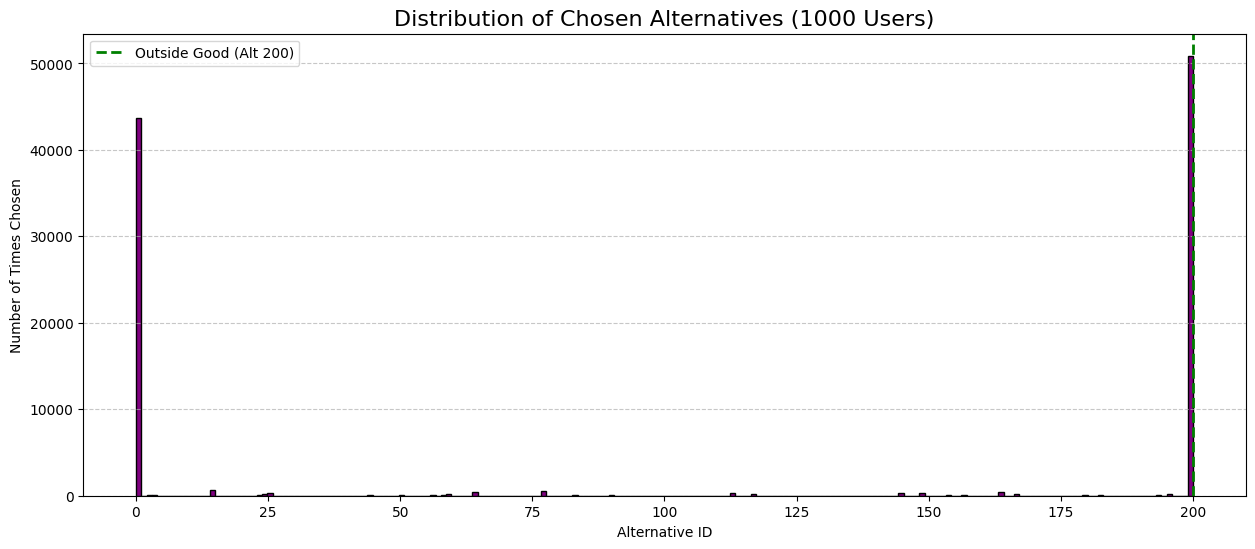

In [ ]:
import cudf
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 6))
plt.hist(choices.get(), bins=n_alternatives_total, color='purple', edgecolor='black')
plt.title('Distribution of Chosen Alternatives (1000 Users)', fontsize=16)
plt.xlabel('Alternative ID')
plt.ylabel('Number of Times Chosen')
plt.axvline(n_alternatives, color='green', linestyle='--', linewidth=2, label=f'Outside Good (Alt {n_alternatives})')
plt.legend()
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

## Using the kernel ( optional)

In [ ]:
choices_store =cudf.DataFrame(choices, columns=["choice",]).reset_index()
choices_store.rename(columns={"index": "user_id"}, inplace=True)
choices_store.to_csv("choices.csv", index=False)


In [ ]:
#use parquet for efficiency
#table of coefficients
#data dumo of all the attributes, ASC